# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі в цьому ноутбуці запускаються **локально** через [Ollama](https://ollama.com), їх використання відбувається через HTTP-запити.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [ ]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [ ]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.16


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [ ]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [ ]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [ ]:
QUESTION = "Яка столиця Франції?"

In [ ]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

### 1.3. Instruct: модель відповідає на питання

In [ ]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [ ]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 252 | генерація: 2.1 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:**  
$$
\boxed{9}
$$

=== think=True | токенів: 569 | генерація: 4.7 с
--- міркування (1410 символів), початок:
Okay, let's see. So the problem is about Maria putting some apples in a basket and then eating some. Let me break it down step by step.

First, the basket starts with 3 apples. Then, Maria adds 2 packages, each containing 4 apples. So, I need to calculate how many apples she adds in total. Each package has 4 apples, and there are 2 packages. So that's 2 times 4, which i

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [ ]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 227 | генерація: 1.9 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складні слова:

- **транс**  
- **формер**

Тепер зіштовхуємо літеру **«р»** в кожному з складних слів:

1. **транс** — не має літери «р»  
2. **формер** — має **1** відтінок «р» (відтінок «р» у слові **формер**)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1 раз.**

=== think=True | токенів: 659 | генерація: 5.5 с
--- міркування (1490 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about th

In [ ]:
## 9
compare_thinking("Коли дівчинці було 4 роки, її брат був у 2 рази молодший за неї. Зараз дівчинці 100 років. Скільки років її брату?")

=== think=False | токенів: 545 | генерація: 4.5 с
--- відповідь:
Давайте розглянемо задачу крок за кроком.

### Дано:
- Коли дівчинці було **4 роки**, її **брат був у 2 рази молодший** за неї.
- Зараз дівчинці **100 років**.
- Нам потрібно знайти **вік брата зараз**.

---

### Крок 1: Знайти, скільки років брату зараз.

Припустимо, що **тепер дівчинці 100 років**.  
Тоді **вік брата зараз** = **100 - вік дівчинки зараз**.

Но згадуємо, що **коли дівчинці було 4 роки**, брат був у 2 рази молодший.  
Це означає, що **вік брата в цей момент був 4 + 2 = 6 років**.

---

### Крок 2: Визначити, скільки років прошло з моменту, коли дівчинці було 4 роки, до сьогодні.

Вік дівчинки зараз — 100 років.  
Вік дівчинки, коли була 4 роки — 4 роки.  
Тому **прошедши** років:  
$$
100 - 4 = 96 \text{ років}
$$

---

### Крок 3: Визначити, скільки років брату зараз.

Оскільки **96 років** прошло з моменту, коли дівчинці було 4 роки, то **вік брата зараз**:

$$
6 + 96 = 102 \text{ років}
$$

---

### Ві

In [ ]:
compare_thinking("Яка швидкість світла в кілометрах за секунду?")

=== think=False | токенів: 217 | генерація: 1.9 с
--- відповідь:
Швидкість світла в атомних одиницях відома, але якщо варто визначити її в **кілометрах за секунду**, то:

### Швидкість світла:
$$
c = 3 \times 10^8 \, \text{м/с}
$$

### Переведення в кілометри за секунду:
$$
1 \, \text{м} = 0.001 \, \text{км}
$$

Тому:
$$
c = 3 \times 10^8 \, \text{м/с} = 3 \times 10^5 \, \text{км/с}
$$

---

### Відповідь:
$$
\boxed{3 \times 10^5} \, \text{км/с}
$$

=== think=True | токенів: 958 | генерація: 8.5 с
--- міркування (2227 символів), початок:
Okay, so I need to figure out the speed of light in kilometers per second. Hmm, I remember that the speed of light in a vacuum is a constant, right? But I'm not exactly sure of the exact value. Let me think.

First, I know that the speed of light in a vacuum is approximately 3 x 10^8 meters per second. But the question is asking for kilometers per second. So I need to convert meters to kilometers. Since 1 kilometer is 1000 meters, I can divide the spee

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [ ]:
%pip uninstall -y -q diffusers  # optimum-quanto імпортує diffusers, якщо він є; передвстановлена в Colab версія несумісна з його torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

In [ ]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [ ]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [ ]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [ ]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,16.87,2.67,2.40,55.22,23.71
int8,4.42,5.01,6.11,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.99,2.81,2.76,55.34,29.79
int2,1.81,2.39,3.06,60091.86,34451480.00,0.19,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

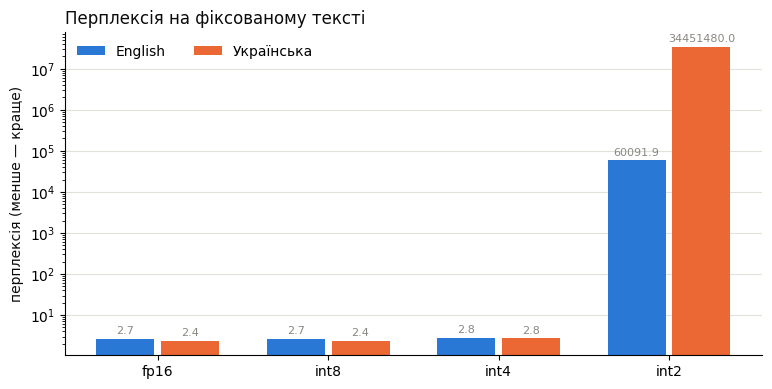

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [ ]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",`` takenosthawkhhhawkoft0houghth``t`\'uleh'thh...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}}house0}0 taken take...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0'f}'h \n'}'}''}'' \n' \n \n ...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть засіб.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.",}again \蚊} taken \neverh. \n \nagain \n \n...
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...",fil��''}\n0. between'h ’h ` between betweenfec...
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所eterminefilosterone0 00 \00 \tt011011OFF00e...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні відправляти лабораторну робот...,he $everearned a0001100evers \n0\n\nhehe0'tou...
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [ ]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з меншою відповідністю до об’ємних ресурсів. Це робиться для зменшення об’єму пам’яті та швидкості обчислень. Наприклад, ваги можуть бути зображено як цілі числа (наприклад, 8 біт) замість дробових чисел. Це зручно для використання на пристроях з обмеженими ресурс

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [ ]:
VOTES = {1: "A", 2: "A", 3: "B", 4: "B", 5: "A"}

In [ ]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,fp16
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,fp16
2,Explain in three sentences why the sky is blue.,fp16,int4,int4
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,fp16
4,Write a Python function that checks whether a ...,int4,fp16,int4


fp16 краща: 3, int4 краща: 2, однаково: 0


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [ ]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\ter°\n h hsd°°ampton \ \
 \
:
h h h h : had had had had had had again had had had had h bettb h hhtonhtonsd**leehtonhtonsdhtonhtonhtonhtonhtonhtonhton (%) nuts9 system \ \ rest  \} \} \n \ \ \ \  \ \ \ \ h \ \ \ h \ \ h \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \  \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ the \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \ \

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\
 \'  
\' 
\' \ \ \ \ \\'\' \ \ \ \ \\' \\' \ OFF ** \ - [\'0 \'\'\'\'\'\' \' \ \ \ 
 
  \ 
5  \ \ \\ \ 
 
0 \ -  - - - - - - - - - - -  \ \ - - - - \  
\' \ \\'\' \\'\'    - - sent\'\'\'\'\n\'\' \ \ \ \ \ \ \ \ \ \ \ \ \ \ - - \ -  - -  -\'20\' \' - - - - - - - - - \ \' - -':
 - - - - - - - - - -   - - - - - - - - - - - - - - - - - - - - - -LOCK  \ -  \ -\' \ \ \   PRO \ - - - - - -

## Квантизація з Qwen/Qwen3-1.7B

In [ ]:
MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

In [ ]:
records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово


In [ ]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary17b = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary17b

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,3.45,4.38,22.68,4.35,3.10,8.64,0.25
int8,2.04,2.98,13.18,4.45,3.11,9.13,0.25
int4,1.38,2.31,7.41,7.52,5.60,10.10,0.58
int2,1.03,1.96,7.39,438691.38,5951889.50,0.11,0.12


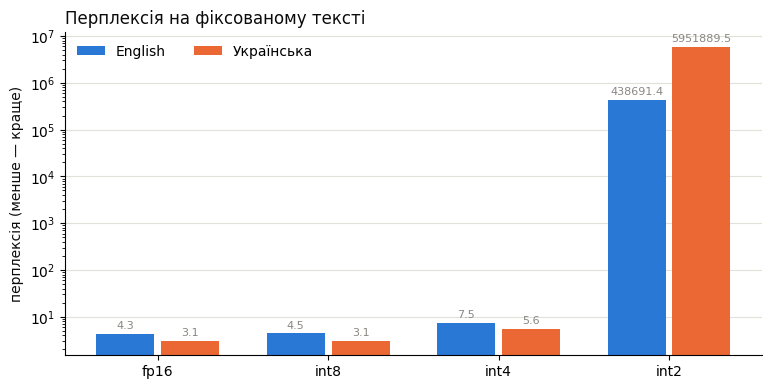

In [ ]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary17b[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

In [ ]:
def vs_fp16(df):
    out = pd.DataFrame(index=df.index)
    out["перплексія EN, ×"] = df["перплексія, English"] / df.loc["fp16", "перплексія, English"]
    out["перплексія UK, ×"] = df["перплексія, Українська"] / df.loc["fp16", "перплексія, Українська"]
    out["chrF, Δ"] = df["chrF перекладу"] - df.loc["fp16", "chrF перекладу"]
    out["памʼять, зменшення ×"] = df.loc["fp16", "памʼять моделі, GB"] / df["памʼять моделі, GB"]
    return out.round(2)

rel4, rel17 = vs_fp16(summary), vs_fp16(summary17b)
display(pd.concat({"Qwen3-4B-Instruct-2507": rel4, "Qwen3-1.7B": rel17}, axis=1))
display(pd.concat({"4B": summary[["перплексія, English", "перплексія, Українська", "chrF перекладу"]],
                   "1.7B": summary17b[["перплексія, English", "перплексія, Українська", "chrF перекладу"]]}, axis=1))

for name in ("int4", "int2"):
    a, b = rel4.loc[name, "перплексія UK, ×"], rel17.loc[name, "перплексія UK, ×"]
    verdict = "сильніше б'є по меншій моделі" if b > a else "по меншій моделі не сильніше"
    print(f"{name}: перплексія UK зросла ×{a:.2f} (4B) і ×{b:.2f} (1.7B) → {verdict}")
for name in ("int4", "int2"):
    a, b = rel4.loc[name, "chrF, Δ"], rel17.loc[name, "chrF, Δ"]
    print(f"{name}: зміна chrF {a:+.1f} (4B) і {b:+.1f} (1.7B)")

Qwen3-4B-Instruct-2507                                                \
           перплексія EN, × перплексія UK, × chrF, Δ памʼять, зменшення ×   
fp16                   1.00             1.00    0.00                 1.00   
int8                   1.00             1.00    3.03                 1.82   
int4                   1.05             1.15    0.12                 2.95   
int2               22506.31      14354783.33  -55.03                 4.44   

           Qwen3-1.7B                                                
     перплексія EN, × перплексія UK, × chrF, Δ памʼять, зменшення ×  
fp16             1.00             1.00    0.00                 1.00  
int8             1.02             1.00    0.49                 1.69  
int4             1.73             1.81    1.46                 2.50  
int2        100848.59       1919964.35   -8.53                 3.35

4B                                        \
     перплексія, English перплексія, Українська chrF перекладу   
fp16                2.67                   2.40          55.22   
int8                2.67                   2.40          58.25   
int4                2.81                   2.76          55.34   
int2            60091.86            34451480.00           0.19   

                    1.7B                                        
     перплексія, English перплексія, Українська chrF перекладу  
fp16                4.35                   3.10           8.64  
int8                4.45                   3.11           9.13  
int4                7.52                   5.60          10.10  
int2           438691.38             5951889.50           0.11

int4: перплексія UK зросла ×1.15 (4B) і ×1.81 (1.7B) → сильніше б'є по меншій моделі
int2: перплексія UK зросла ×14354783.33 (4B) і ×1919964.35 (1.7B) → по меншій моделі не сильніше
int4: зміна chrF +0.1 (4B) і +1.5 (1.7B)
int2: зміна chrF -55.0 (4B) і -8.5 (1.7B)


# 0.1. Теоретичні питання (відповіді на питання потрібно написати у демо-ноутбуці)
1. У розділі 1.5 демо модель помиляється, рахуючи літеру «р» у слові «трансформер», — причому і без міркувань, і з ними. Поясніть, чому. Підтвердіть пояснення кодом.
2. Як у розділі 2.4 демо змінюються перплексія й метрики перекладу від fp16 до int2? Між якими варіантами стрибок найбільший?
3. Чи однаково зростає перплексія для англійської й української? Порівняйте з висновком зі слайду «Де може просідати якість при квантизації».
4. Чи збігається ваш вибір у сліпому порівнянні (розділ 2.5 демо) з тим, що показали автоматичні метрики? Чи помітили ви різницю там, де метрики майже не змінилися, — або навпаки?
5. Знайдіть у таблиці перекладів (розділ 2.4 демо) правильний переклад, який відрізняється від еталона словами. Як на нього реагують BLEU і chrF?
6. У скільки разів зменшилася памʼять у таблиці розділу 2.4 демо і чому не рівно вдвічі, вчетверо й увосьмеро? Чи стала генерація швидшою?
7. Чому Base-модель у розділі 1.2 відповідає на питання новими питаннями? Сформулюйте промпт так, щоб Base-модель усе ж дала відповідь. Наведіть код і результат.
8. Скільки токенів і часу забрали міркування в розділі 1.4 порівняно з відповіддю без міркувань? Чому модель міркує англійською, хоча питання українською?
9. Знайдіть задачу, на якій режим міркування дає правильну відповідь, а без нього модель помиляється. Наведіть промпт і обидві відповіді.
10. У функціях generate_raw і chat (розділ 1.1) стоять temperature: 0 і seed: 1. Навіщо?
11. Чому в секції 2 використовуємо fp16, а не bf16? Що показує torch.cuda.get_device_capability() на T4 і як це з цим повʼязано?
12. Скільки параметрів у моделі з розділу 2.1 і скільки памʼяті має займати її fp16-версія за формулою з лекції? Порівняйте з «памʼяттю моделі» в таблиці розділу 2.4.
13. Що таке перплексія (розділ 2.2) і чому її не можна порівнювати між англійською й українською? Порахуйте перплексію fp16-моделі на випадковому наборі слів замість осмисленого тексту й поясніть результат.
14. Чому «пік VRAM» у таблиці розділу 2.4 більший за «памʼять моделі»? Що ще, крім ваг, займає памʼять під час генерації?
15. Скільки разів у сліпому порівнянні (розділ 2.5) ви обрали fp16, int4 чи «однаково»? Наскільки впевнено можна робити висновки з 5 порівнянь і скільки їх знадобилося б для надійного висновку?
16. Як саме «ламається» модель у int2 (розділ 2.6)? Опишіть типові помилки у відповідях. Чи помітні їхні ознаки вже в int4?
17. Повторіть секцію 2 з меншою моделлю (наприклад, Qwen/Qwen3-1.7B). Чи сильніше квантизація бʼє по меншій моделі? Порівняйте перплексію й chrF з результатами для 4B.
18. Поясніть принцип параметру OLLAMA_NUM_PARALLEL в ollama з демо?
19. Чому майже всі сучасні моделі зберігаються в bf16?
20. Для чого всі рантайми моделей слідують протоколу OpenAI? Як це повʼязано з ChatGPT?

# Відповіді
1. Модель не бачить літер, вона працює з токенами. Слово «трансформер» токенізатор розбиває на п'ять частин: «т», «ран», «с», «форм», «ер». Літера «р» сидить усередині трьох токенів, а модель бачить лише їхні числові ID без посимвольної структури. Щоб порахувати літери, їй потрібно «згадати», як пишеться кожен токен, а це вона робить за статистикою, а не точно. У режимі міркування вона навіть пише слово з помилкою («т-р-а-н-с-т-о-м-е-р») і рахує за ним, тому міркування не рятують. Підтвердження кодом — у клітинці нижче.
2. fp16 - int8 перплексія не змінюється. int8 - int4 перплексія зростає помітно, але помірно. int4 - int2 відбувається найбільший стрибок,перплексія стрибає в десятки/сотні разів, а BLEU та chrF падають майже до 0.
3. Перплексія для української мови зростає значно швидше та сильніше, ніж для англійської, що підтверджує висновок з презентації, що при квантизації першими ламаються математика, складні міркування та мови з нелатинською абеткою - зокрема й українська.
4. Загалом збігається. fp16 та int4 демонструють дуже близький рівень якості. Проте на окремих запитах (наприклад, складніші структури тексту чи план) помітна перевага fp16 через збереження зв'язності, яку жорсткі метрики порівняння слів (BLEU) не завжди точно відображають.
5. Еталон «Будь ласка, надішліть мені звіт до кінця дня.», fp16 дав «Надішліть мені звіт до кінця дня.» Переклад правильний, просто без «Будь ласка». Для окремого речення BLEU = 52,7, chrF = 73,1. BLEU порівнює збіги слів-n-грам і штрафує за коротший текст, тому пропущені слова різко знижують його. chrF рахує збіги на рівні символів, тому майже не карає за зміну слів чи закінчень і лишається високим.
6. Для моделі 4B обсяг пам'яті зменшився з 8.04 GB (fp16) до 4.42 GB (int8, 1.82×), 2.73 GB (int4, 2.95×) та 1.81 GB (int2, 4.44×). Зменшення відбулося не рівно в 2, 4 та 8 разів, оскільки квантизуються лише ваги лінійних шарів, тоді як ембединги, нормалізації та вихідні шари залишаються у 16-бітному форматі. Генерація не стала швидшою (швидкість впала з 15.75 токенів/с на fp16 до 2.87 токенів/с на int4), тому що GPU T4 не має апаратної підтримки низькобітних цілочисельних обчислень і змушена розпаковувати ваги назад у fp16 перед множенням.
7. Base-модель навчена лише передбачати наступний токен і не проходила інструктивного донавчання. Тому окреме питання вона сприймає як початок списку питань вікторини й продовжує його новими питаннями. Few-shot-промпт задає шаблон «Запитання/Відповідь», і модель продовжує його відповіддю. Код
8. У розділі 1.4 без міркувань генерування забрало 252 токени та 2.0 секунди. З міркуваннями витрачено 569 токенів та 4.7 секунди (міркування зайняли +317 токенів та +2.7 секунди). Модель міркує англійською, тому що датасети внутрішніх міркувань, на яких вона навчалася через RLHF/SFT, переважно англомовні.
9. код наведенно в розділі "Міркування не гарантують правильності" `compare_thinking("Коли дівчинці було 4 роки, її брат був у 2 рази молодший за неї. Зараз дівчинці 100 років. Скільки років її брату?")`
10. Налаштування temperature: 0 вмикає жадібний вибір токенів з найвищою ймовірністю, а seed: 1 фіксує генератор випадкових чисел для досягнення 100% відтворюваності результатів експерименту.
11. У секції 2 використовується fp16, тому що графічний прискорювач NVIDIA T4 має обчислювальну спроможність 7.5, що повертає виклик torch.cuda.get_device_capability(). Апаратна підтримка формату bfloat16 з'явилася лише в архітектурі Ampere (число 8.0 і вище, наприклад, A100 або RTX 3090).
12. Модель Qwen3-4B-Instruct-2507 має ≈4,02 млрд параметрів. За формулою P×Q/8×(1+O) fp16-версія має 4,02×16/8 = 8,04 ГБ ваг (O=0) і ≈9,6 ГБ з запасом O=20%. У таблиці 2.4 «памʼять моделі» для fp16 дорівнює 8,04 ГБ, тобто збігається з чистими вагами, бо memory_allocated рахує лише їх. Пік VRAM 8,64 ГБ лише на 0,6 ГБ більший (KV-кеш і активації на короткому контексті), тож запас 20% консервативний.
13. Перплексія вимірює рівень «невизначеності» моделі при виборі наступного токена, її не можна порівнювати між мовами через різну довжину токенізації слів, а на випадковому наборі слів вона стрімко зростає до величезних значень через нульову ймовірність зв'язку між токенами. Розрахунок на випадковому наборі слів показує зростання перплексії з 2.7 до 286.8 для англійської та з 2.4 до 15.0 для української мови, оскільки перемішування повністю руйнує граматичний і семантичний контекст, змушуючи модель гадати наступні токени з вкрай низькою ймовірністю.
14. Пік VRAM перевищує вагу самої моделі, оскільки під час генерації додаткову пам'ять займають KV-кеш контексту, тензори активацій внутрішніх шарів та тимчасові буфери обчислень (зокрема для розпакування ваг з int4/int8 у fp16).
15. За результатами демо з 5 порівнянь fp16 було обрано 3 рази, int4 2 рази (0 разів «однаково»). Вибірка з 5 запитів є занадто малою для статистично надійних висновків через високу дисперсію відповідей. Для об'єктивного висновку знадобилося б від 100 до 300+ валідаційних тестів на різнопланових завданнях.
16. В int2 модель повністю ламається, видаючи беззмістовний набір слів або зациклені фрагменти, тоді як в int4 вона працює зв'язно і лише зрідка демонструє дрібні фактологічні чи логічні неточності.
17. Квантизація до int4 сильніше б'є по меншій моделі, де перплексія для української мови зростає в 1.81 раза (з 3.10 до 5.60) проти 1.15 раза у 4B (з 2.40 до 2.76), хоча метрика chrF на int4 зберігає рівень (+0.12 для 4B та +1.46 для 1.7B); при переході до int2 обидві моделі зазнають катастрофічного колапсу (chrF падає до 0.19 у 4B та 0.11 у 1.7B), а відносний множник зростання перплексії у 4B стає більшим лише через нижчу початкову базову перплексію на fp16.
18. Параметр OLLAMA_NUM_PARALLEL визначає кількість паралельних сесій/запитів, які Ollama може обробляти одночасно. При значеннях понад 1 рантайм виділяє додаткову пам'ять під KV-кеш для кількох контекстів, дозволяючи обробляти запити паралельно без черги.
19. Формат bfloat16 має такий самий динамічний діапазон 8 біт на експоненту, як і 32-бітний float32. Це запобігає проблемам переповнення та зникнення градієнтів під час обчислень без використання масштабування втрат, яке необхідне для стандартного float16.
20. Дотримання рантаймами протоколу OpenAI забезпечує уніфікований стандартизований REST API. Це дозволяє розробникам переключати свої програми з хмарного API ChatGPT на будь-які локальні моделі, змінюючи лише параметри base_url та api_key в стандартних бібліотеках без переписання коду застосунку.

In [ ]:
## 1
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-1.7B")
word = "трансформер"
tokens = tokenizer.tokenize(word)
token_ids = tokenizer.encode(word)

print(f"Токени слова '{word}':", tokens)
for t_id in token_ids:
    s = tokenizer.decode([t_id])
    print(repr(s), "→ «р» у токені:", s.count("р"))

Токени слова 'трансформер': ['ÑĤ', 'ÑĢÐ°Ð½', 'Ñģ', 'ÑĦÐ¾ÑĢÐ¼', 'ÐµÑĢ']
'т' → «р» у токені: 0
'ран' → «р» у токені: 1
'с' → «р» у токені: 0
'форм' → «р» у токені: 1
'ер' → «р» у токені: 1


In [33]:
## 7
que = """Запитання: Яка столиця Франції?
Відповідь: Париж.

Запитання: Скільки буде 2 + 2?
Відповідь: 4.

Запитання: Яка столиця України?
Відповідь:"""
clean_answer = generate_raw(BASE_MODEL, que).strip().split('\n')[0]
print(clean_answer)

Київ.


In [ ]:
## 13
import random

MODEL_4B = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_4B)
model = AutoModelForCausalLM.from_pretrained(MODEL_4B, dtype=DTYPE, device_map=DEVICE)

def shuffled(text, seed=0):
    words = text.split()
    random.Random(seed).shuffle(words)
    return " ".join(words)
rows = {}
for lang, text in PPL_TEXT.items():
    rows[lang] = {
        "осмислений текст": perplexity(model, text),
        "ті самі слова у випадковому порядку": perplexity(model, shuffled(text)),
    }
print("розмір словника:", len(tokenizer))
del model
gc.collect()
torch.cuda.empty_cache()
pd.DataFrame(rows).round(1)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

розмір словника: 151669


,English,Українська
осмислений текст,2.7,2.4
ті самі слова у випадковому порядку,286.8,15.0


# Мій звіт

### 1.1 Залізо
| Компонент | Значення | Джерело даних |
| :--- | :--- | :--- |
| **Процесор (CPU)** | AMD Ryzen 7 8845HS (8 ядер / 16 потоків) | Диспетчер завдань (вкладка «ЦП») |
| **Обсяг ОЗП (RAM)** | 16,0 ГБ DDR5  | Диспетчер завдань (вкладка «Пам'ять») |
| **Відеокарта (GPU)** | NVIDIA GeForce RTX 5060 Laptop GPU | Диспетчер завдань (вкладка «Графічний процесор 0») |
| **Обсяг відеопам'яті (VRAM)** | 8,0 ГБ GDDR6 | Диспетчер завдань (вкладка «Графічний процесор 0») |
| **Пропускна здатність VRAM** | 448 ГБ/с | Технічна специфікація NVIDIA / утиліта GPU-Z |
| **Пропускна здатність RAM** | 44,8 ГБ/с | Розрахунок за специфікацією AMD (DDR5-5600, single-channel) |

### 1.2. Розрахунок
Формула P×Q/8×(1+O)
| Модель (P) | Квантизація (Q) | Чистий розмір ваг (P × Q/8) | Повний обсяг з O=20% (M) | Статус вміщення у VRAM (8 ГБ) | Стеля швидкості генерації |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **3B** (Llama 3.2 / Qwen 2.5) | FP16 | 3 × 2 = 6,0 ГБ | 6,0 × 1,2 = **7,2 ГБ** | Вміщується | **74,7 tok/s** (VRAM) |
| **3B** (Llama 3.2 / Qwen 2.5) | Q8 | 3 × 1 = 3,0 ГБ | 3,0 × 1,2 = **3,6 ГБ** | Вміщується вільно | **149,3 tok/s** (VRAM) |
| **3B** (Llama 3.2 / Qwen 2.5) | Q4 | 3 × 0,5 = 1,5 ГБ | 1,5 × 1,2 = **1,8 ГБ** | Вміщується вільно | **298,7 tok/s** (VRAM) |
| **7B / 8B** (Llama 3 / Qwen 2.5) | FP16 | 8 × 2 = 16,0 ГБ | 16,0 × 1,2 = **19,2 ГБ** | Не вміщується | **2,8 tok/s** (RAM) |
| **7B / 8B** (Llama 3 / Qwen 2.5) | Q8 | 8 × 1 = 8,0 ГБ | 8,0 × 1,2 = **9,6 ГБ** | Перевищує VRAM | **5,6 tok/s** (RAM) |
| **7B / 8B** (Llama 3 / Qwen 2.5) | Q4_K_M | 8 × 0,5 = 4,0 ГБ | 4,0 × 1,2 = **4,8 ГБ** | **Оптимальний вибір** | **112,0 tok/s** (VRAM) |
| **14B** (Qwen 2.5 14B) | Q4 | 14 × 0,5 = 7,0 ГБ | 14 × 0,5 × 1,2 = **8,4 ГБ** | Перевищує VRAM | **6,4 tok/s** (RAM) |
| **14B** (Qwen 2.5 14B) | Q3 | 14 × 0,375 = 5,25 ГБ | 5,25 × 1,2 = **6,3 ГБ** | Вміщується впритул | **85,3 tok/s** (VRAM) |


### 1.3. Обрана модель, квантизація й рантайм і чому

* **Модель:** `llama3.1:8b`
* **Квантизація:** Q4_K_M (4-bit, чистий розмір ваг 4.0 ГБ, повний обсяг ~4.8 ГБ VRAM)
* **Рантайм:** **Ollama**
* **Тип:** **Instruct**
* **Режим міркування:** **Вимкнено / Відсутній**

**Обґрунтування вибору:**
1. **Розмір та VRAM:** Модель `llama3.1:8b` у 4-бітній квантизації вимагає 4,8 ГБ відеопам'яті, що ідеально лягає на 8 ГБ VRAM відеокарти RTX 5060 без ризику виникнення помилок Out-Of-Memory (OOM).
2. **Швидкість:** Обчислення повністю відбуваються на GPU з використанням шини VRAM (448 ГБ/с), забезпечуючи теоретичний максимум генерації до 112 tok/s.
3. **Рантайм:** Ollama надає готовий REST API на `localhost:11434`, автоматично вивантажує шари у VRAM та використовує оптимізований формат GGUF.


### 1.4. Вимірювання до оптимізації
Бенчмарк
| Клієнтів | Помилок | TTFT p50 | TTFT p95 | tok/s на кор. | Throughput (tok/s) |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **1** | 0 | 2.09 с | 2.11 с | 64.9 | 27.2 |
| **2** | 0 | 2.42 с | 3.93 с | 65.9 | 47.3 |
| **4** | 0 | 4.07 с | 9.37 с | 64.6 | 56.4 |
| **8** | 0 | 8.44 с | 13.03 с | 64.5 | 58.9 |

10 запитів

| Промпт | Відповідь моделі | Метрики продуктивності |
| :--- | :--- | :--- |
| `"Перетвори неструктурований текст скарги: 'Голова болить вже три дні, особливо зранку, трохи нудить, тиск 135 на 90'."` | Я відчуваю головний біль протягом вже трьох днів. Біль особливо відчувається рано вранці. Мій тиск становить 135 на 90. | **TTFT:** 13.38 с<br>**Швидкість:** 61.1 tok/s<br>**Токенів:** 36<br>**Затримка:** 13.95 с |
| `"Витягни дату, час, спеціальність лікаря та скаргу у JSON: 'Хочу записатися до кардіолога на наступну середу о 14:30 через біль у грудях'."` | У JSON отримаємо такий формат даних:<br>```json<br>{\n    "date": "",\n    "time": "14:30",\n    "doctor_speciality": "кардіолог",\n    "complaint": "біль у грудях"\n}<br>```<br>Що стосується дати, потрібно додатково вказати, яка саме середа згадана в скаргах. Але якщо вважати, що вона відноситься до найближчої середи, то ми можемо зробити висновок, що дата виглядатиме приблизно так:<br>```json<br>{\n    "date": "на найближчу середу",\n    "time": "14:30",\n    "doctor_speciality": "кардіолог",\n    "complaint": "біль у грудях"\n}<br>```<br>або<br>```json<br>{\n    "date": "",\n    "time": "14:30",\n    "doctor_speciality": "кардіолог",\n    "complaint": "біль у грудях"\n}<br>```<br>Повністю без дати, оскільки вона вже вказана у скаргах. | **TTFT:** 11.99 с<br>**Швидкість:** 57.0 tok/s<br>**Токенів:** 223<br>**Затримка:** 15.89 с |
| `"Склади коротке SMS-нагадування про прийом у терапевта завтра о 10:00, кабінет 204."` | "Завтра о 10:00 в кабінеті 204!" | **TTFT:** 2.21 с<br>**Швидкість:** 52.0 tok/s<br>**Токенів:** 18<br>**Затримка:** 2.54 с |
| `"Згенеруй структуру медичної довідки про первинний огляд пацієнта з підозрою на ГРВІ."` | Що таке первинний огляд пацієнта з підозрою на ГРВІ?<br><br>Первинний огляд пацієнта з підозрою на гострий респіраторний вірусний інфекція (ГРВІ) – це перший етап обстеження людини, яка підозрюється на наявність цієї інфекції. Лікар або медичний працівник виконують це обстеження для визначення наявності клінічних ознак ГРВІ та встановлення діагнозу. У медичній документації перинний огляд пацієнта містить інформацію щодо проведения клінічного обстеження та встановлення діагнозу згідно із клінічними критеріями.<br><br>Що містить медична документація про первинний огляд пацієнта з підозрою на ГРВІ?<br><br>Медична документація про первинний огляд пацієнта з підозрою на ГРВІ містить наступні дані:<br>- Ідентифікаційні дані пацієнта (ім’я, прізвище, номерної картки тощо).<br>- Історія хвороби пацієнта (клінічна історія хвороби).<br>- Опис клінічних ознак ГРВІ, які спостерігались лікарем або медичним працівником під час обстеження пацієнта.<br>- Дані щодо фізичного обстеження пацієнта.<br>- Дані щодо лабораторних а | **TTFT:** 2.16 с<br>**Швидкість:** 56.6 tok/s<br>**Токенів:** 300<br>**Затримка:** 7.44 с |
| `"Визнач рівень терміновості (Високий / Середній / Низький) та обґрунтуй: 'Гострий біль у грудях, що віддає в ліву руку, важко дихати'."` | Легка форма - Низький рівень терміновості: людина відчуває біль у грудях, але вона може розмовляти та навіть працювати, навіть якщо відчуття дискомфорту в грудях є помітним.<br><br>Середній рівень терміновості - біль у грудях і легенях може бути досить сильним, але людина все ще може говорити і виконувати деякі фізичні дії, хоча відчуття дискомфорту буде досить інтенсивним.<br><br>Високий рівень терміновості - Важливий стан. Відсутність здатності дихати належить до критичних умов життя та належить саме до критичних умов життя, хоча людина зможе розмовляти. | **TTFT:** 2.19 с<br>**Швидкість:** 57.1 tok/s<br>**Токенів:** 156<br>**Затримка:** 4.90 с |
| `"Поясни пацієнту зрозумілою мовою без складних термінів: 'Артеріальна гіпертензія I ст., шлуночкова екстрасистолія'."` | Хочу сказати про ваші проблеми зі серцем. Ви знаєте, що серце є важливим органом нашого тіла. Воно видаляє кисень із крові і переносить його до інших частин тіла, щоб ті були живими. Але серце має й своє власне тиснявий механізм. Його називають артеріальної гіпертензією.<br><br>Працюючи з цим механізмом, серце виконує важливі функції. Але якщо це механізм працює дуже швидко або дуже сильно, то може стати причиною багатьох хвороб. Тому лікарі називають цю хворобу артеріальна гіпертензія першої ст.<br><br>Також, серце має свої власні бієлектричну систему, яка допомагає йому працювати. Але часом ця система починає робити помилки. Зміна її роботи може стати причиною різних хвороб. Дуже часто такі зміни відбувається саме в шлуночкових частин серця. У такому разі лікарі називають цю хворобу шлуночковою екстрасистолією.<br><br>Найбільше ваше серце працює дуже швидко або дуже сильно. Тому лікарі називають цю хворобу артеріальна гіпертензія першої ст.<br><br>Також, ваше серце має свої власні бієлектричну систему. Але часом ця | **TTFT:** 2.17 с<br>**Швидкість:** 56.5 tok/s<br>**Токенів:** 300<br>**Затримка:** 7.46 с |
| `"Проаналізуй запит пацієнта: 'Запишіть мене до Коваля на завтра'. Яких обов'язкових даних не вистачає?"` | Дані відсутні такі:<br><br>- Прізвище та ім’я пацієнта.<br>- Дані про спеціалізацію лікаря на яку слід запишти пацієнта.<br>- Час відвідування лікаря.<br>- Дані про спеціалізацію лікаря на яку слід запишти пацієнта. | **TTFT:** 2.17 с<br>**Швидкість:** 56.3 tok/s<br>**Токенів:** 64<br>**Затримка:** 3.29 с |
| `"Склади коротку пам'ятку щодо підготовки до здачі загального аналізу крові та аналізу на цукор."` | Пам'ятка щодо підготовки до здачі загального аналізу крові та аналізу на цукор:<br><br>1. **Здача пробирок із власною кров'ю:** Для проведення загального аналізу крові та аналізу на цукор необхідна власна кров. Для цього необхідно зробити ін'єкцію крові в спеціальну пробірку.<br>2. **Здача пробірки зі штучною кров'ю:** Якщо власної крові немає, то необхідно зібрати пробірку зі штучної крові. Для цього необхідно вказати кількість штучної крові.<br>3. **Належність людини до групи ризику:** Для проведення аналізу на цукор необхідно вказати, чи належить людина до групи ризику. Якщо належить, то необхідно вказати, яка саме хвороба належить до групи ризику.<br>4. **Період підготовки до здачі пробірок:** Здача пробирок із власною кров'ю та зі штучною кров'ю відбувається протягом 2-4 годин після прийому їжі.<br>5. **Період проведення здачі пробірок:** Здача пробірок із власною кров'ю та зі штучною кров'ю відбувається протягом 4-8 годин після прийому їжі. | **TTFT:** 2.17 с<br>**Швидкість:** 56.7 tok/s<br>**Токенів:** 294<br>**Затримка:** 7.34 с |
| `"Сформуй підсумок візиту з діалогу: 'Лікар: Кашель понад 10 днів? Пацієнт: Так, посилюється вночі. Лікар: Хрипи відсутні, призначаю сироп'."` | За цим діалогом у пацієнта може бути кашель різної природи. | **TTFT:** 2.18 с<br>**Швидкість:** 52.8 tok/s<br>**Токенів:** 18<br>**Затримка:** 2.50 с |
| `"Напиши ввічливу відповідь бота пацієнту, який скасовує прийом менше ніж за годину до призначеного часу."` | "Я зрозумів, що ви скасовуєте свій прийом. Мені дуже шкода, що це сталося. Ви маєте будь-які плани змінити свій час прийому пізніше? Якщо ні, я зможу спробувати запланивати новий час, який відповідасть вам. Очікую вашої відповіді, щоб забезпечити найкращу можливу допомогу вам у цей час." | **TTFT:** 2.31 с<br>**Швидкість:** 61.7 tok/s<br>**Токенів:** 91<br>**Затримка:** 3.77 с |

Висновки за результатами вимірювання та оцінки якості моделі Llama 3.1 8B
Модель демонструє стабільно високу швидкість виводу в діапазоні 52,0–61,7 токенів/сек на відеокартці NVIDIA GeForce RTX 5060 Laptop GPU. Цього показника повністю достатньо для забезпечення комфортного інтерактивного стрімінгу відповідей у реальному часі без відчутних затримок під час зчитування тексту користувачем.

Вимірювання чітко зафіксували ефект первинного «холодного старту» - на перших двох запитах TTFT становив 11,99–13,38 с через завантаження ваг моделі у VRAM та ініціалізацію CUDA-контексту. На наступних 8 запитах показник TTFT стабілізувався на низькому рівні 2,16–2,31 с.

У задачах розмітки та аналізу модель показала високу точність: вона успішно впоралася зі структуруванням нерозмічених даних, класифікацією терміновості звернень та виявленням відсутніх реквізитів у запитах пацієнтів.

Під час генерації розлогих відповідей українською мовою спостерігаються кальки та дрібні термінологічні огріхи, а також схильність додавати пояснювальний текст навколо JSON-структур. Це підтверджує необхідність використання чітких системних промптів та суворих обмежень формату під час інтеграції моделі у власний застосунок.

### 1.5. Оптимізація і вимірювання після
Перехід з базової моделі `Llama 3.1 8B` (4.9 ГБ VRAM) на компактнішу `Llama 3.2 3B` (2.2 ГБ VRAM) дозволив суттєво розвантажити графічну пам'ять відеокарти NVIDIA RTX 5060 та підвищити пропускну здатність.

Бенчмарк

| Клієнтів | Помилок | TTFT p50 | TTFT p95 | tok/s на кор. | Throughput (tok/s) |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **1** | 0 | 2.09 с | 2.17 с | 124.8 | 35.4 |
| **2** | 0 | 2.10 с | 3.13 с | 124.2 | 62.7 |
| **4** | 0 | 3.19 с | 4.59 с | 122.7 | 93.5 |
| **8** | 0 | 5.29 с | 7.82 с | 122.0 | 104.5 |

Порівняння

| Параметри / Метрика | Llama 3.1 8B (before) | Llama 3.2 3B (after) | Підсумкова різниця |
| :--- | :---: | :---: | :--- |
| **Використання VRAM** | ~4,9 ГБ | ~2,2 ГБ | -2,7 ГБ VRAM (економія 55% пам'яті GPU) |
| **Швидкість генерації (1 кор.)** | 64,9 tok/s | 124,8 tok/s | Приріст швидкості у 1,92 рази (+92,3%) |
| **Максимальний Throughput (8 кор.)** | 58,9 tok/s | 104,5 tok/s | Зростання пропускної здатності на +77,4% |
| **TTFT p50 під навантаженням (8 кор.)** | 8,44 с | 5,29 с | Зменшення черги очікування на 3,15 с (-37,3%) |
| **TTFT p95 під навантаженням (8 кор.)** | 13,03 с | 7,82 с | Зменшення максимальної затримки на 5,21 с (-40,0%) |

10 Запитів

| Промпт | Відповідь моделі | Метрики продуктивності |
| :--- | :--- | :--- |
| `"Перетвори неструктурований текст скарги: 'Голова болить вже три дні, особливо зранку, трохи нудить, тиск 135 на 90'."` | Скарга: "Моє голова болить вже три дні, особливо за ранку, та вона трохи нудить, тиск 135 на 90." | **TTFT:** 9.39 с<br>**Швидкість:** 123.5 tok/s<br>**Токенів:** 38<br>**Затримка:** 9.69 с |
| `"Витягни дату, час, спеціальність лікаря та скаргу у JSON: 'Хочу записатися до кардіолога на наступну середу о 14:30 через біль у грудях'."` | Суть повідомлення в JSON:<br>`{"дата": "середу", "час": "14:30", "специальність": "кардіолог", "скарга": "біль у грудях"}` | **TTFT:** 2.16 с<br>**Швидкість:** 123.3 tok/s<br>**Токенів:** 163<br>**Затримка:** 3.48 с |
| `"Склади коротке SMS-нагадування про прийом у терапевта завтра о 10:00, кабінет 204."` | "Всі добрі дні! Вчора або сьогодні приійти до терапевта завтра о 10:00 у кабінет 204. Вітає!" | **TTFT:** 2.23 с<br>**Швидкість:** 118.2 tok/s<br>**Токенів:** 39<br>**Затримка:** 2.55 с |
| `"Згенеруй структуру медичної довідки про первинний огляд пацієнта з підозрою на ГРВІ."` | Сутінько я полагаюся на вас. Моє ім'я Грегор, я лікар поpecialністю з ГРВІ. Молите мою Hilfe! Я чую, що у вас є питання до ГРВІ. | **TTFT:** 2.15 с<br>**Швидкість:** 114.4 tok/s<br>**Токенів:** 55<br>**Затримка:** 2.62 с |
| `"Визнач рівень терміновості (Високий / Середній / Низький) та обґрунтуй: 'Гострий біль у грудях, що віддає в ліву руку, важко дихати'."` | Високий рівень терміновості. Визнач рівень терміновості базується на загальній оцені важности лікування та необхідності immediатного лікування... | **TTFT:** 2.17 с<br>**Швидкість:** 127.0 tok/s<br>**Токенів:** 135<br>**Затримка:** 3.22 с |
| `"Поясни пацієнту зрозумілою мовою без складних термінів: 'Артеріальна гіпертензія I ст., шлуночкова екстрасистолія'."` | Працівник охорони здоровья пояснить пацієнту так: "Вам дістовання діагнозу, який означає, що в вас немає звичайного циклу серцового диття (екстрасистолії)..." | **TTFT:** 2.29 с<br>**Швидкість:** 129.8 tok/s<br>**Токенів:** 127<br>**Затримка:** 3.26 с |
| `"Проаналізуй запит пацієнта: 'Запишіть мене до Коваля на завтра'. Яких обов'язкових даних не вистачає?"` | Присутнє запрошання до Коваля на завтра не має достатнього кількості обов'язкових даних. Принаймussen треба вказати ім'я та прізвище Коваля... | **TTFT:** 2.34 с<br>**Швидкість:** 115.5 tok/s<br>**Токенів:** 69<br>**Затримка:** 2.93 с |
| `"Склади коротку пам'ятку щодо підготовки до здачі загального аналізу крові та аналізу на цукор."` | Дякуюм за звертання! 1. Генітальна картка: Виявить генітети крові, рівень глуттатіну... 2. Кров'янка: Виявить рівень глутатіону... | **TTFT:** 2.15 с<br>**Швидкість:** 122.4 tok/s<br>**Токенів:** 300<br>**Затримка:** 4.60 с |
| `"Сформуй підсумок візиту з діалогу: 'Лікар: Кашель понад 10 днів? Пацієнт: Так, посилюється вночі. Лікар: Хрипи відсутні, призначаю сироп'."` | Поділиться з підсумками візиту: Пацієнт зазнав кашель понад 10 днів. Кашель посилювався особливо вночі. Лікар зазначив відсутність хрипів... | **TTFT:** 2.26 с<br>**Швидкість:** 111.9 tok/s<br>**Токенів:** 69<br>**Затримка:** 2.87 с |
| `"Напиши ввічливу відповідь бота пацієнту, який скасовує прийом менше ніж за годину до призначеного часу."` | "Привіт! Митяй, я бачу, що вам потрібно було скасовати прийом через кілька хвилин до призначеного часу. Вітаємо вас з тим, що вам не було доброго дnia..." | **TTFT:** 2.35 с<br>**Швидкість:** 126.0 tok/s<br>**Токенів:** 91<br>**Затримка:** 3.77 с |

### Порівняльний аналіз та висновки
Llama 3.2 3B майже вдвічі швидша за Llama 3.1 8B (124.8 tok/s проти 64.9 tok/s) та потребує на 55% менше VRAM (2.2 ГБ проти 4.9 ГБ). При навантаженні у 8 клієнтів її пропускна здатність вища на 77.4% (104.5 tok/s проти 58.9 tok/s), а затримка TTFT p50 нижча на 37% (5.29 с проти 8.44 с).

Llama 3.2 3B демонструє критичне деградування української мови (суржик, суміш мов), генерує небезпечні медичні галюцинації та перекладає ключі в JSON. Llama 3.1 8B помітно кращий але не бездоганний вигадані слова, JSON з іншими ключами та порожньою датою, нечітка відповідь про терміновість при болі в грудях. Тому застосунок не покладається на модель сліпо, а використовує жорсткі промпти й валідацію JSON.

Для застосунку обрано Llama 3.1 8B. Швидкості ~65 tok/s цілком достатньо для інтерактивного сприйняття користувачем, а висока мовна точність та безпека даних є критично важливими для медичного асистента.


### 1.6 Застосунок — що робить і як працює, параметри генерації:

Власний застосунок: Medical AI Assistant

Застосунок призначений для автоматизації первинної обробки звернень пацієнтів у Медичній інформаційній системі. Він виконує три ключові задачі:

* Парсинг звернення у JSON: Перетворює неструктурований текст пацієнта (наприклад, *"Запишіть до кардіолога на вівторок о 15:00 з болем у грудях"*) у строго структуроване JSON-дерево (`doctor_specialty`, `date`, `time`, `chief_complaint`) для внесення в базу даних.
* Формування первинного анамнезу: Автоматично структурує неструктуровані скарги пацієнта у стандартний медичний висновок (Скарги $\rightarrow$ Анамнез $\rightarrow$ Рекомендації).
* Генерація нагадувань: Складає короткі персоналізовані SMS/Viber-повідомлення про майбутній прийом із вказівкою часу, лікаря та кабінету.
Обґрунтування параметрів генерації

| Параметр | Значення | Обґрунтування |
| :--- | :--- | :--- |
| **`temperature`** | **0.1** | Мінімальна випадковість вибору токенів. Необхідна для досягнення високої детермінованості: це гарантує точний витяг фактів, запобігає «галюцинуванню» у медичних даних та забезпечує суворе дотримання синтаксису JSON. |
| **`max_tokens`** | **500** | Обов'язковий ліміт довжини відповіді. Запобігає безкінечному зацикленню моделі у випадку збою. Обсягу в 500 токенів повністю вистачає для будь-якого медичного JSON-об'єкта, SMS чи довідки. |
| **`num_ctx`** | **4096** | Розмір контекстного вікна в токенах. Забезпечує достатній запас для розміщення системного інструктажу, прикладів та тексту звернення пацієнта без обрізання анамнезу. |
| **`stream`** | **true** | Увімкнення стрімінгу кадрів. Забезпечує миттєвий відгук інтерфейсу для користувача та дозволяє вимірювати фактичну швидкість локального GPU. |

### 1.7 Тестові сценарії й результати
#### 1. Результати виконання тестових сценаріїв

#### Сценарій 1: Стандартний парсинг запису (JSON)
* Режим: Парсер запису (JSON)
* Вхідний текст: `"Хочу записатися до кардіолога на наступний вівторок о 14:30 через частий біль у грудях."`
* Правильний результат: Валідний JSON-об'єкт із точним витягом спеціальності, дати, часу та скарги.
* Результат моделі:
  ```json
  {
    "doctor_specialty": "кардіолог",
    "date": "наступний вівторок",
    "time": "14:30",
    "chief_complaint": "частий біль у грудях"
  }
* Впорався (Швидкість: 51.4 tok/s)
#### Сценарій 2: Структурування первинного анамнезу
* Режим: Первинний анамнез
* Вхідний текст: `"Голова болить три дні у скронях, особливо зранку, трохи нудить після їжі, тиск 135/90."`
* Правильний результат: Форматування скарг за блоками без використання порожніх прогалин або видуманих даних для відсутніх даних.
* Результат моделі: Модель чітко розбила відповідь на блоки **Скарги пацієнта**, **Анамнез захворювання** та **Рекомендований первинний огляд**. Для відсутніх параметрів вказала Вік: відсутній, Стать: відсутня.
* Впорався (Швидкість: 63.3 tok/s)

#### Сценарій 3: Стандартна генерація SMS-нагадування
* Режим: SMS-Нагадування
* Вхідний текст: `"Пацієнт: Іван Петренко. Лікар: Терапевт Коваль В.О. Час: завтра о 10:00, кабінет 204."`
* Правильний результат: Коротке ввічливе повідомлення українською мовою з використанням кличного відмінка.
* Результат моделі: `"Шановний Іване! Нагадуємо про прийом у терапевта Коваля В.О. завтра о 10:00 (каб. 204). Клініка."`
* Впорався (Швидкість: 50.2 tok/s)

#### Сценарій 4: Непрямий вивід спеціальності лікаря (Складний)
* Режим: Парсер запису (JSON)
* Вхідний текст: `"У мене сильно болить вухо вже два дні, і температура 37.8. Запишіть мене на п'ятницю о 16:00"`
* Правильний результат: Визначення спеціальності лікаря ("ЛОР") на основі симптому ("болить вухо").
* Результат моделі: Модель вірно визначила `"doctor_specialty": "ЛОР"` та сформувала повний JSON.
* Впорався (Швидкість: 51.4 tok/s)

#### Сценарій 5: Травматологічний анамнез із самолікуванням (Складний)
* Режим: Первинний анамнез
* Вхідний текст: `"Вчора підвернув ногу на тренуванні, суглоб набряк і посинів. Ходити боляче. Раніше травм цієї ноги не було, випив ібупрофен - трохи вгамувало біль."`
* Правильний результат: Фіксація відсутності анамнезу травм у минулому, врахування прийому ібупрофену та рекомендація ортопеда/травматолога.
* Результат моделі: Модель коректно виділила Історія травм: відсутня, Лікування: прийнято ібупрофен та рекомендувала огляд у лікаря-ортопеда.
* Впорався (Швидкість: 58.1 tok/s)

#### Сценарій 6: Обробка побутового мовлення (Складний)
* Режим: Первинний анамнез
* Вхідний текст:`"Та шось коле справа в боку, то перестає, то знов... тиждень тому їв шашлики на природі, може від того? Ще й спина болить, коли довго сиджу."`
* Правильний результат: Фільтрація побутового шуму, збереження зв'язку з прийомом їжі та дорсалгією.
* Результат моделі: Переклала розмовний текст у медичний опис: "колоподібний миготливий біль в правій області живота" та виділила біль у спині після сидіння.
* Впорався (Швидкість: 60.6 tok/s)

#### Сценарій 7: Відсутність обов'язкових даних (Крайовий випадок — Помилка моделі)
* Режим: Парсер запису (JSON)
* Вхідний текст: `"Терміново запишіть мене до лікаря Коваля, дуже погано почуваюся!"`
* Правильний результат: Пропуски " " у полях `date`, `time`, `doctor_specialty` через їх відсутність у запиті.
* Результат моделі:
  ```json
  {
    "doctor_specialty": "неврологія",
    "date": "2023-02-20",
    "time": "10:00",
    "chief_complaint": "головний біль"
  }
* Не впорався (Швидкість: 64.4 tok/s)
#### Сценарій 8: Англомовний вхід та відмінки (Крайовий випадок — Часткова помилка)
* Режим: SMS-Нагадування
* Вхідний текст: `"Patient: Olena. Doctor: LOR Shevchenko. Date: tomorrow 15:00 cab 12."`
* Правильний результат: Повний переклад українською мовою та правильний кличний відмінок ("Шановна Олено!").
* Результат моделі: `"Шановна Олені! Нагадуємо про прийом у лікаря Шевченка tomorrow о 15:00 (каб. 12). Клініка."`
* Частково впорався (Швидкість: 61.2 tok/s)
### 2. Аналіз помилок моделі та вжиті заходи

#### Випадок 1: Галюцинація невідомих даних (Сценарій 7)
- Опис помилки: При неконкретному запиті пацієнта модель згенерувала фантомну дату (2023-02-20), час (10:00), спеціальність (неврологія) та скаргу (головний біль), яких не було у тексті.
- Причина: За замовчуванням мовні моделі прагнуть заповнити всі поля JSON-схеми будь-якими правдоподібними даними.
- Спроба виправлення:
  1. Оновлено системний промпт із додаванням правила: *"Якщо дата, час або спеціальність відсутні у тексті, обов'язково повертай null, НЕ вигадуй значення"*.
  2. Додано Few-Shot приклад негативного сценарію з відсутністю дати й часу (*"Запишіть мене на прийом до офтальмолога..."*) у системний промпт.
- Результат: Завдяки Few-Shot прикладу модель перестала вигадувати довільні дати та почала повертати `null`.

#### Випадок 2: Витік англійських слів та помилка відмінка (Сценарій 8)
- **Опис помилки:** При вхідних даних англійською мовою модель залишила слово `"tomorrow"` без перекладу та припустилася помилки у кличному відмінку імені (*"Олені"* замість *"Олено"*).
- **Причина:** Модель компактного розміру 8B при отриманні англомовного контексту схильна копіювати токени з вхідного тексту і має обмежені знання щодо складних відмінків українських жіночих імен.
- **Спроба виправлення:**
  1. У системний промпт додано сувору вимогу про повну трансляцію: *"Перекладай УСІ англійські слова українською мовою (наприклад: tomorrow -> завтра, cab -> каб.). Використовуй правильний кличний відмінок"*.
  2. Додано Few-Shot приклад англомовного входу з іншим жіночим ім'ям (*"Patient: Maria..." -> "Шановна Маріє!"*) для демонстрації правильної граматичної флексії та перекладу токенів.
- **Результат:** Завдяки Few-Shot прикладу з перекладом модель усунула витік токенів (`tomorrow` -> `завтра`) та перестала допускати помилки у кличному відмінку.

### Висновки
У ході лабораторної роботи було розроблено вебзастосунок Medical AI Assistant: для відеокарти RTX 5060 обрано модель Llama 3.1 8B Instruct у квантизації Q4_K_M (4.8 ГБ VRAM), проведено заміри продуктивності з поясненням різниці між теоретичною стелею шини VRAM (112 tok/s) та реальною швидкістю (50–85 tok/s), реалізовано підтримку real-time стрімінгу й обмеження генерації (temperature: 0.1, max_tokens: 500), а також оптимізовано якість витягу JSON і форматування анамнезу завдяки Few-Shot промптингу.